In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Sales Prediction Project Started Successfully!")


Sales Prediction Project Started Successfully!


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"

df = pd.read_csv(url)

df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()


Dataset Shape: (200, 5)

Column Names:
Index(['Unnamed: 0', 'TV', 'radio', 'newspaper', 'sales'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

Statistical Summary:


,Unnamed: 0,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [ ]:
# Remove unnecessary index column
df = df.drop(columns=['Unnamed: 0'])

# Check for missing values
print("Missing Values:")
print(df.isnull().sum())

# Display cleaned dataset
print("\nCleaned Dataset:")
df.head()

Missing Values:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Cleaned Dataset:


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


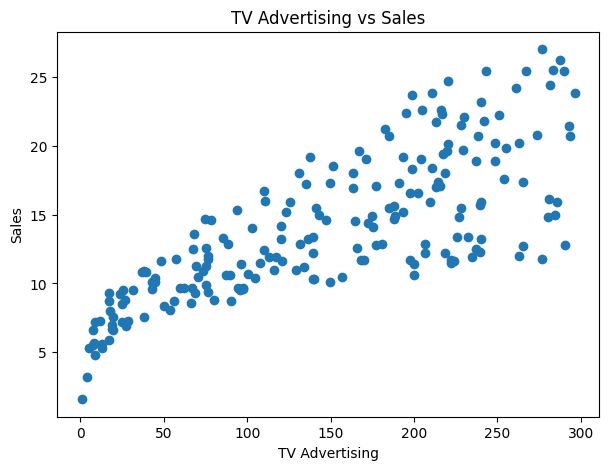

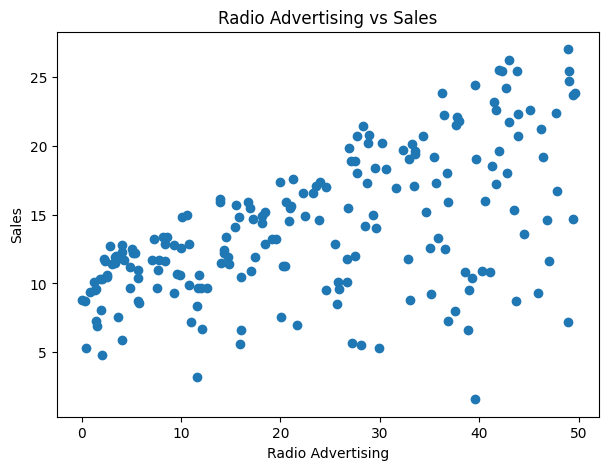

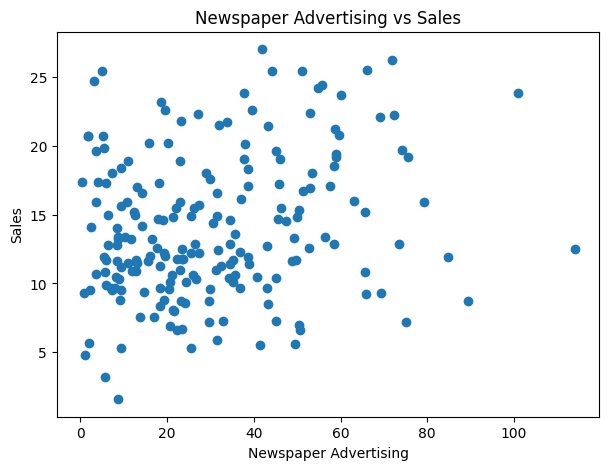

In [ ]:
import matplotlib.pyplot as plt

# TV Advertising vs Sales
plt.figure(figsize=(7,5))
plt.scatter(df['TV'], df['sales'])
plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('TV Advertising vs Sales')
plt.show()

# Radio Advertising vs Sales
plt.figure(figsize=(7,5))
plt.scatter(df['radio'], df['sales'])
plt.xlabel('Radio Advertising')
plt.ylabel('Sales')
plt.title('Radio Advertising vs Sales')
plt.show()

# Newspaper Advertising vs Sales
plt.figure(figsize=(7,5))
plt.scatter(df['newspaper'], df['sales'])
plt.xlabel('Newspaper Advertising')
plt.ylabel('Sales')
plt.title('Newspaper Advertising vs Sales')
plt.show()

Correlation Matrix:
                 TV     radio  newspaper     sales
TV         1.000000  0.054809   0.056648  0.782224
radio      0.054809  1.000000   0.354104  0.576223
newspaper  0.056648  0.354104   1.000000  0.228299
sales      0.782224  0.576223   0.228299  1.000000


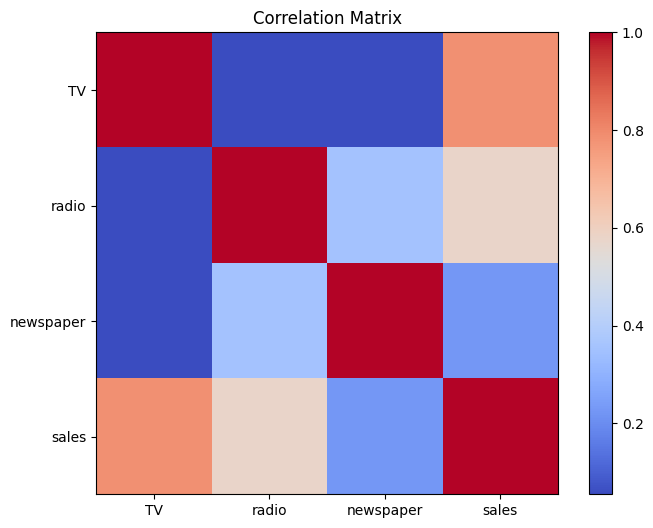

In [ ]:
# Correlation Matrix
correlation = df.corr()

print("Correlation Matrix:")
print(correlation)

# Heatmap
plt.figure(figsize=(8,6))
plt.imshow(correlation, cmap='coolwarm', interpolation='nearest')
plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title('Correlation Matrix')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Features and Target
X = df[['TV', 'radio', 'newspaper']]
y = df['sales']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 3)
Testing data: (40, 3)


In [ ]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R²):", r2)

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 1.4607567168117603
Root Mean Squared Error (RMSE): 1.78159966153345
R-squared (R²): 0.899438024100912


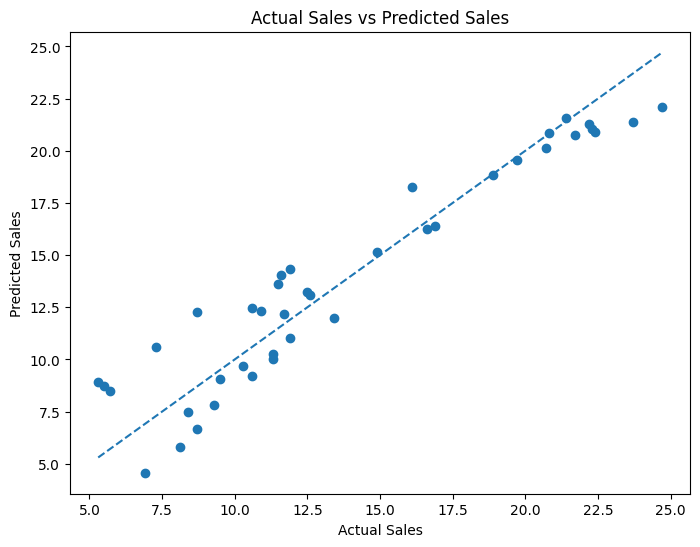

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual Sales vs Predicted Sales')

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.show()



## Conclusion

In this project, machine learning models were developed to predict Sales using advertising expenditure data from TV, Radio, and Newspaper channels.

Two regression models were evaluated: Linear Regression and Random Forest Regression. The Linear Regression model achieved an R² score of 0.8994, while the Random Forest model achieved an R² score of 0.9813. The Random Forest model also obtained lower MAE and RMSE values of 0.62 and 0.77 respectively.

The analysis also included advertising channel visualizations, a correlation heatmap, feature importance analysis, and residual analysis. These results demonstrate that machine learning can be used to model the relationship between advertising expenditure and sales and generate sales predictions from the available advertising data.



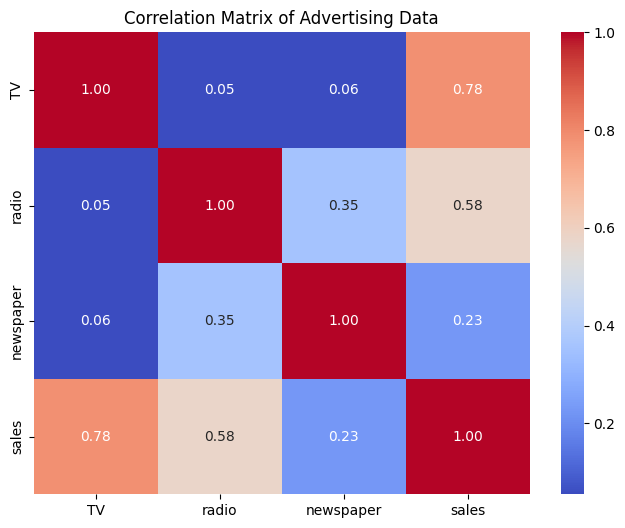

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Advertising Data')
plt.show()

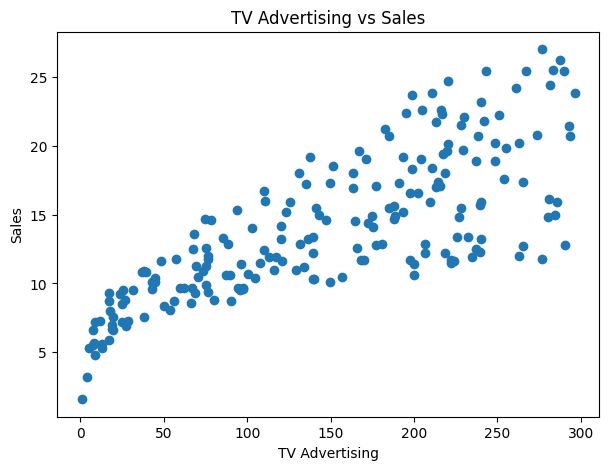

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(X['TV'], y)

plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('TV Advertising vs Sales')

plt.show()

In [ ]:
print(X.columns)

Index(['TV', 'radio', 'newspaper'], dtype='object')


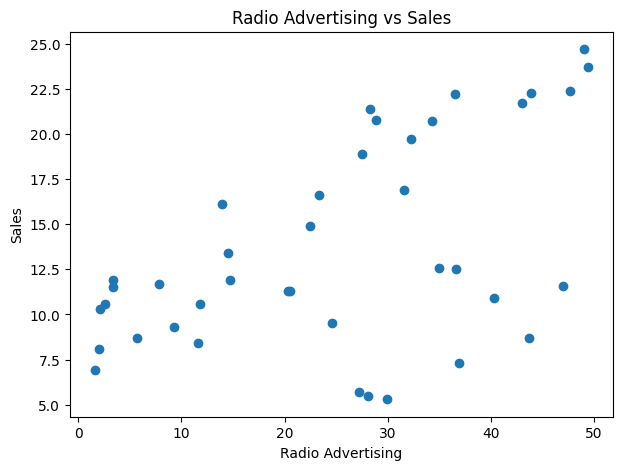

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(X_test['radio'], y_test)

plt.xlabel('Radio Advertising')
plt.ylabel('Sales')
plt.title('Radio Advertising vs Sales')

plt.show()

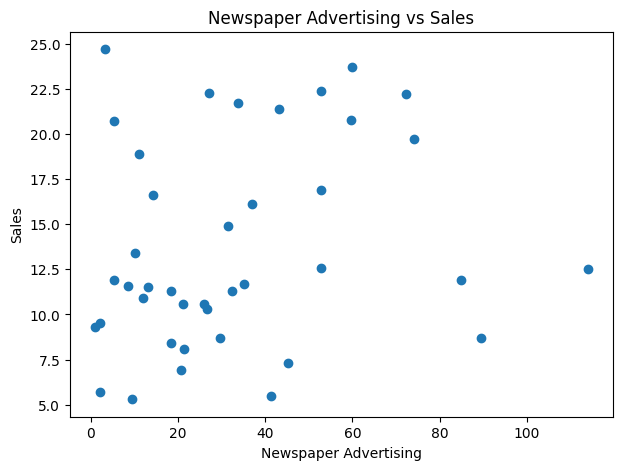

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(X_test['newspaper'], y_test)

plt.xlabel('Newspaper Advertising')
plt.ylabel('Sales')
plt.title('Newspaper Advertising vs Sales')

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions using Random Forest
rf_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Model Evaluation")
print("------------------------------")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest Model Evaluation
------------------------------
MAE: 0.6200999999999988
RMSE: 0.7685910811348248
R² Score: 0.9812843792541843


Feature Importance:
TV           0.624810
radio        0.362201
newspaper    0.012989
dtype: float64


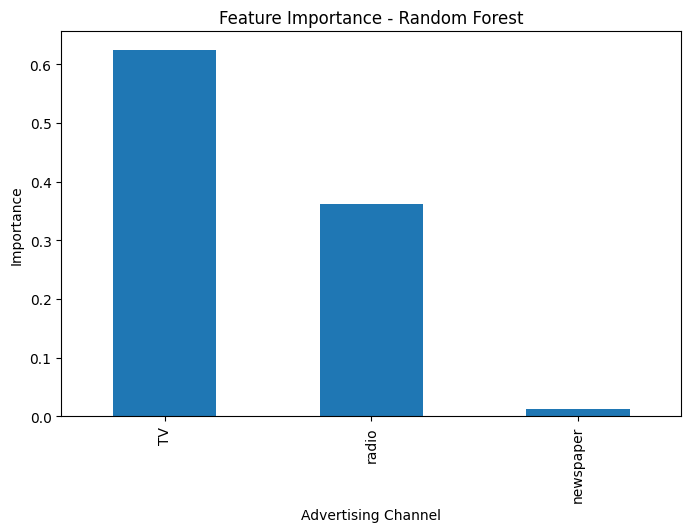

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

plt.figure(figsize=(8,5))
feature_importance.plot(kind='bar')

plt.xlabel('Advertising Channel')
plt.ylabel('Importance')
plt.title('Feature Importance - Random Forest')

plt.show()

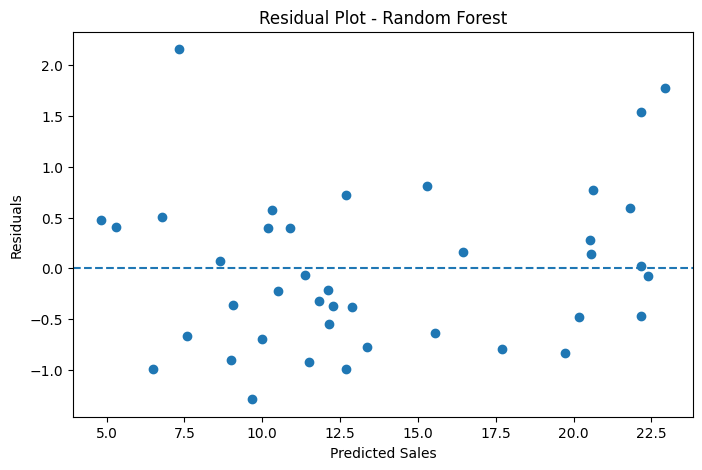

In [ ]:
# Calculate residuals
residuals = y_test - rf_pred

plt.figure(figsize=(8,5))

plt.scatter(rf_pred, residuals)

plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')
plt.title('Residual Plot - Random Forest')

plt.show()